# Random Forest — Prediksi Tingkat Kemacetan Lalu Lintas di Waktu Tertentu
Notebook ini (1) membangun Random Forest dari nol dengan *Gain Ratio* (C4.5) sesuai langkah perhitungan manual,
(2) memverifikasi hasilnya, dan (3) **menghasilkan model `rf_kemacetan.joblib`** yang dipakai backend web simulasi.

| Isi | Keterangan |
|---|---|
| Nama / NIM / Kelas | Muhamad Rafli Ardiansyah / 301240028 / 5B |


Bisa dijalankan di Google Colab atau lokal (Jupyter). Jalankan semua sel dari atas ke bawah.

## 1. Persiapan

In [1]:
import sys, math, random, importlib
from pathlib import Path
import joblib
import pandas as pd

# Deteksi lokasi: di folder project (notebook/) atau Colab (folder kerja saat ini)
BASE = Path('..') if Path('../simulation').exists() else Path('.')
for d in ['simulation', 'data', 'models']:
    (BASE / d).mkdir(parents=True, exist_ok=True)

# Parameter hutan (sama dengan default web simulasi)
N_TREES = 3
M_ATTR  = 2
SEED    = 3
print('BASE =', BASE.resolve())

BASE = /content


## 2. Dataset
14 data kondisi lalu lintas. Target: **Kemacetan** (`Macet` / `Lancar`).

In [2]:
CSV_TEXT = '''No,Waktu,Hari,Cuaca,Acara,Kemacetan
1,Pagi,Hari Kerja,Cerah,Tidak,Macet
2,Pagi,Hari Kerja,Hujan,Tidak,Macet
3,Siang,Hari Kerja,Cerah,Tidak,Lancar
4,Sore,Hari Kerja,Cerah,Tidak,Macet
5,Sore,Hari Kerja,Hujan,Ada,Macet
6,Malam,Hari Kerja,Cerah,Tidak,Lancar
7,Pagi,Akhir Pekan,Cerah,Tidak,Lancar
8,Siang,Akhir Pekan,Cerah,Ada,Macet
9,Sore,Akhir Pekan,Hujan,Ada,Macet
10,Malam,Akhir Pekan,Cerah,Ada,Macet
11,Siang,Hari Kerja,Hujan,Tidak,Macet
12,Malam,Akhir Pekan,Hujan,Tidak,Lancar
13,Pagi,Akhir Pekan,Hujan,Tidak,Lancar
14,Sore,Akhir Pekan,Cerah,Tidak,Lancar
'''
(BASE / 'data' / 'kemacetan.csv').write_text(CSV_TEXT, encoding='utf-8')
df = pd.read_csv(BASE / 'data' / 'kemacetan.csv')
df

,No,Waktu,Hari,Cuaca,Acara,Kemacetan
0,1,Pagi,Hari Kerja,Cerah,Tidak,Macet
1,2,Pagi,Hari Kerja,Hujan,Tidak,Macet
2,3,Siang,Hari Kerja,Cerah,Tidak,Lancar
3,4,Sore,Hari Kerja,Cerah,Tidak,Macet
4,5,Sore,Hari Kerja,Hujan,Ada,Macet
5,6,Malam,Hari Kerja,Cerah,Tidak,Lancar
6,7,Pagi,Akhir Pekan,Cerah,Tidak,Lancar
7,8,Siang,Akhir Pekan,Cerah,Ada,Macet
8,9,Sore,Akhir Pekan,Hujan,Ada,Macet
9,10,Malam,Akhir Pekan,Cerah,Ada,Macet


## 3. Mesin Random Forest (dari nol)
Sel ini menulis `simulation/rf_engine.py`. File yang sama dipakai backend Flask, sehingga hasil notebook dan web identik.

In [3]:
ENGINE_SRC = r'''"""
rf_engine.py
Mesin Random Forest (C4.5 / Gain Ratio) yang dibuat dari nol.
Dipakai oleh: notebook (membuat model .joblib) dan backend Flask (web simulasi).
Studi kasus: Prediksi Tingkat Kemacetan Lalu Lintas di Waktu Tertentu.
"""
import csv
import math
import random

TARGET = "Kemacetan"
CLASSES = ["Lancar", "Macet"]
ATTRS = ["Waktu", "Hari", "Cuaca", "Acara"]
DOMAINS = {
    "Waktu": ["Pagi", "Siang", "Sore", "Malam"],
    "Hari": ["Hari Kerja", "Akhir Pekan"],
    "Cuaca": ["Cerah", "Hujan"],
    "Acara": ["Tidak", "Ada"],
}


# ---------------------------------------------------------------- data
def load_csv(path):
    with open(path, newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        r["No"] = int(r["No"])
    return rows


# ---------------------------------------------------------- perhitungan
def class_counts(rows):
    return {c: sum(1 for r in rows if r[TARGET] == c) for c in CLASSES}


def entropy(counts):
    n = sum(counts.values())
    if n == 0:
        return 0.0
    h = -sum((c / n) * math.log2(c / n) for c in counts.values() if c > 0)
    return h if h > 1e-12 else 0.0  # hindari -0.0


def majority(counts):
    # seri -> Macet (kelas terakhir pada CLASSES)
    return max(CLASSES, key=lambda c: (counts[c], CLASSES.index(c)))


def analyze_attribute(rows, attr, h_total):
    n = len(rows)
    present = {r[attr] for r in rows}
    values = []
    for v in DOMAINS[attr]:
        if v not in present:
            continue
        sub = [r for r in rows if r[attr] == v]
        cnt = class_counts(sub)
        share = len(sub) / n
        values.append({
            "value": v,
            "n": len(sub),
            "counts": cnt,
            "entropy": entropy(cnt),
            "split_part": (-share * math.log2(share)) if share < 1 else 0.0,
        })
    gain = h_total - sum((x["n"] / n) * x["entropy"] for x in values)
    if abs(gain) < 1e-12:
        gain = 0.0
    split_info = sum(x["split_part"] for x in values)
    ratio = gain / split_info if split_info > 0 else 0.0
    return {"gain": gain, "split_info": split_info, "gain_ratio": ratio, "values": values}


# ---------------------------------------------------------------- pohon
def build_node(rows, available, rng, m, path, logs):
    counts = class_counts(rows)
    n = len(rows)
    nonzero = [c for c in CLASSES if counts[c] > 0]
    if len(nonzero) == 1:
        return {"type": "leaf", "label": nonzero[0], "n": n, "counts": counts, "reason": "pure"}
    if not available:
        return {"type": "leaf", "label": majority(counts), "n": n, "counts": counts, "reason": "no_attr"}

    h_total = entropy(counts)
    candidates = rng.sample(available, min(m, len(available)))
    analysis = {a: analyze_attribute(rows, a, h_total) for a in candidates}
    best = max(candidates, key=lambda a: analysis[a]["gain_ratio"])
    if len(analysis[best]["values"]) < 2:
        return {"type": "leaf", "label": majority(counts), "n": n, "counts": counts, "reason": "no_split"}

    log_id = len(logs)
    logs.append({
        "id": log_id,
        "path": [list(p) for p in path],
        "n": n,
        "counts": counts,
        "entropy": h_total,
        "candidates": candidates,
        "analysis": analysis,
        "best": best,
    })
    node = {"type": "node", "attr": best, "n": n, "counts": counts,
            "log_id": log_id, "majority": majority(counts), "children": []}
    rest = [a for a in available if a != best]
    for item in analysis[best]["values"]:
        v = item["value"]
        sub = [r for r in rows if r[best] == v]
        child = build_node(sub, rest, rng, m, path + [(best, v)], logs)
        node["children"].append({"value": v, "node": child})
    return node


def build_forest(data, n_trees=3, m=2, seed=7):
    rng = random.Random(seed)
    trees = []
    for t in range(n_trees):
        idx = [rng.randrange(len(data)) for _ in range(len(data))]
        sample = [data[i] for i in idx]
        logs = []
        tree = build_node(sample, list(ATTRS), rng, m, [], logs)
        trees.append({
            "index": t + 1,
            "bootstrap_idx": idx,
            "bootstrap_rows": sample,
            "tree": tree,
            "logs": logs,
        })
    return {"meta": {"n_trees": n_trees, "m": m, "seed": seed, "n_data": len(data),
                     "attrs": ATTRS, "classes": CLASSES, "target": TARGET,
                     "domains": DOMAINS},
            "trees": trees}


# ------------------------------------------------------------- prediksi
def predict_tree(node, sample):
    path = []
    while node["type"] == "node":
        v = sample[node["attr"]]
        nxt = next((c for c in node["children"] if c["value"] == v), None)
        if nxt is None:  # nilai tidak pernah muncul pada node ini -> suara mayoritas node
            return node["majority"], path, node
        path.append({"attr": node["attr"], "value": v})
        node = nxt["node"]
    return node["label"], path, node


def predict_forest(forest, sample):
    votes = []
    for t in forest["trees"]:
        label, path, _ = predict_tree(t["tree"], sample)
        votes.append({"tree": t["index"], "label": label, "path": path})
    counts = {c: sum(1 for v in votes if v["label"] == c) for c in CLASSES}
    return {"votes": votes, "counts": counts, "final": majority(counts)}


# ------------------------------------------------------------ visualisasi
def draw_tree(tree, path=None, title=None, figsize=None, dpi=160):
    """Gambar pohon keputusan dengan matplotlib (opsional: sorot jalur prediksi)."""
    import copy
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, Ellipse

    tree = copy.deepcopy(tree)  # jangan ubah pohon asli
    path = path or []
    pos, edges, order = {}, [], []
    counter = [0]

    def layout(node, depth, on_path, prefix):
        nid = len(order)
        order.append(node)
        node["_id"] = nid
        node["_on"] = on_path
        if node["type"] == "leaf":
            pos[nid] = (counter[0], -depth)
            counter[0] += 1
            return nid
        kids = []
        for i, ch in enumerate(node["children"]):
            follow = on_path and i_follow(node, ch, prefix)
            cid = layout(ch["node"], depth + 1, follow, prefix + [ch["value"]])
            kids.append((cid, ch["value"], follow))
        xs = [pos[k[0]][0] for k in kids]
        pos[nid] = (sum(xs) / len(xs), -depth)
        for cid, val, follow in kids:
            edges.append((nid, cid, val, follow))
        return nid

    def i_follow(node, ch, prefix):
        step = len(prefix)
        return step < len(path) and path[step]["attr"] == node["attr"] and path[step]["value"] == ch["value"]

    layout(tree, 0, True, [])
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    w = max(6.0, (max(xs) - min(xs) + 1) * 1.75)
    h = max(3.2, (-min(ys) + 1) * 1.45 + 0.6)
    fig, ax = plt.subplots(figsize=figsize or (w, h))
    for a, b, val, follow in edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1 - 0.18, y2 + 0.2], color="#E8603C" if follow else "#9ACD6A",
                lw=2.6 if follow else 1.4, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.02, val, fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none"), zorder=3)
    for nid, node in enumerate(order):
        x, y = pos[nid]
        hl = bool(path) and node["_on"]
        if node["type"] == "node":
            ax.add_patch(Ellipse((x, y), 1.45, 0.52, fc="#6AA84F", ec="#E8603C" if hl else "#4E8A38",
                                 lw=2.4 if hl else 1, zorder=2))
            ax.text(x, y, node["attr"], color="white", fontsize=9, fontweight="bold",
                    ha="center", va="center", zorder=4)
        else:
            color = "#E05555" if node["label"] == "Macet" else "#92D050"
            ax.add_patch(FancyBboxPatch((x - 0.38, y - 0.2), 0.76, 0.4,
                                        boxstyle="round,pad=0.02,rounding_size=0.08", fc=color,
                                        ec="#E8603C" if hl else color, lw=2.4 if hl else 1, zorder=2))
            ax.text(x, y, node["label"], color="white", fontsize=9, fontweight="bold",
                    ha="center", va="center", zorder=4)
    ax.set_xlim(min(xs) - 0.9, max(xs) + 0.9)
    ax.set_ylim(min(ys) - 0.6, 0.6)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10, style="italic")
    fig.tight_layout()
    return fig
'''
(BASE / 'simulation' / 'rf_engine.py').write_text(ENGINE_SRC, encoding='utf-8')
sys.path.insert(0, str((BASE / 'simulation').resolve()))
importlib.invalidate_caches()
import rf_engine as rf
importlib.reload(rf)
print('rf_engine siap:', rf.ATTRS, '->', rf.TARGET)

rf_engine siap: ['Waktu', 'Hari', 'Cuaca', 'Acara'] -> Kemacetan


## 4. Langkah 1 — Bootstrap sampling
Pengambilan acak **berpengembalian** sebanyak n = 14 untuk setiap pohon.

In [4]:
data = rf.load_csv(BASE / 'data' / 'kemacetan.csv')
forest = rf.build_forest(data, n_trees=N_TREES, m=M_ATTR, seed=SEED)
for t in forest['trees']:
    print(f"Pohon {t['index']} -> data terambil (No asal):", [i + 1 for i in t['bootstrap_idx']])
pd.DataFrame(forest['trees'][0]['bootstrap_rows'])

Pohon 1 -> data terambil (No asal): [4, 10, 9, 3, 6, 10, 8, 11, 10, 2, 10, 1, 14, 8]
Pohon 2 -> data terambil (No asal): [11, 14, 3, 4, 11, 3, 14, 9, 7, 12, 1, 11, 13, 2]
Pohon 3 -> data terambil (No asal): [12, 13, 7, 7, 12, 13, 10, 8, 3, 6, 2, 1, 3, 8]


,No,Waktu,Hari,Cuaca,Acara,Kemacetan
0,4,Sore,Hari Kerja,Cerah,Tidak,Macet
1,10,Malam,Akhir Pekan,Cerah,Ada,Macet
2,9,Sore,Akhir Pekan,Hujan,Ada,Macet
3,3,Siang,Hari Kerja,Cerah,Tidak,Lancar
4,6,Malam,Hari Kerja,Cerah,Tidak,Lancar
5,10,Malam,Akhir Pekan,Cerah,Ada,Macet
6,8,Siang,Akhir Pekan,Cerah,Ada,Macet
7,11,Siang,Hari Kerja,Hujan,Tidak,Macet
8,10,Malam,Akhir Pekan,Cerah,Ada,Macet
9,2,Pagi,Hari Kerja,Hujan,Tidak,Macet


## 5. Langkah 2–3 — Entropy, Gain, Split Info, Gain Ratio per node
Setiap node memilih `m = 2` atribut acak, lalu atribut dengan **Gain Ratio tertinggi** dipilih sebagai pemisah.

In [5]:
def fmt(x): return f"{x:.5f}".replace('.', ',')

def show_log(log):
    nama = 'Root' + ''.join(f' > {a}={v}' for a, v in log['path'])
    print(f"Node: {nama}  (n={log['n']}, {log['counts']})  Entropy total = {fmt(log['entropy'])}")
    print('  Atribut acak (m):', ', '.join(log['candidates']))
    for a in log['candidates']:
        r = log['analysis'][a]
        print(f"  {a:<6} Gain={fmt(r['gain'])}  SplitInfo={fmt(r['split_info'])}  GainRatio={fmt(r['gain_ratio'])}")
        for v in r['values']:
            c = v['counts']
            print(f"     - {v['value']:<12} n={v['n']}  Lancar={c['Lancar']} Macet={c['Macet']}  Entropy={fmt(v['entropy'])}")
    print('  => Dipilih:', log['best'], '\n')

for t in forest['trees']:
    print('=' * 70, f"\nPOHON {t['index']}\n", '=' * 70)
    for lg in t['logs']:
        show_log(lg)

POHON 1
Node: Root  (n=14, {'Lancar': 3, 'Macet': 11})  Entropy total = 0,74960
  Atribut acak (m): Cuaca, Acara
  Cuaca  Gain=0,08539  SplitInfo=0,74960  GainRatio=0,11392
     - Cerah        n=11  Lancar=3 Macet=8  Entropy=0,84535
     - Hujan        n=3  Lancar=0 Macet=3  Entropy=0,00000
  Acara  Gain=0,25698  SplitInfo=1,00000  GainRatio=0,25698
     - Tidak        n=7  Lancar=3 Macet=4  Entropy=0,98523
     - Ada          n=7  Lancar=0 Macet=7  Entropy=0,00000
  => Dipilih: Acara 

Node: Root > Acara=Tidak  (n=7, {'Lancar': 3, 'Macet': 4})  Entropy total = 0,98523
  Atribut acak (m): Waktu, Cuaca
  Waktu  Gain=0,41380  SplitInfo=1,95021  GainRatio=0,21218
     - Pagi         n=2  Lancar=0 Macet=2  Entropy=0,00000
     - Siang        n=2  Lancar=1 Macet=1  Entropy=1,00000
     - Sore         n=2  Lancar=1 Macet=1  Entropy=1,00000
     - Malam        n=1  Lancar=1 Macet=0  Entropy=0,00000
  Cuaca  Gain=0,29169  SplitInfo=0,86312  GainRatio=0,33795
     - Cerah        n=5  Lancar=3 M

## 6. Visualisasi pohon keputusan

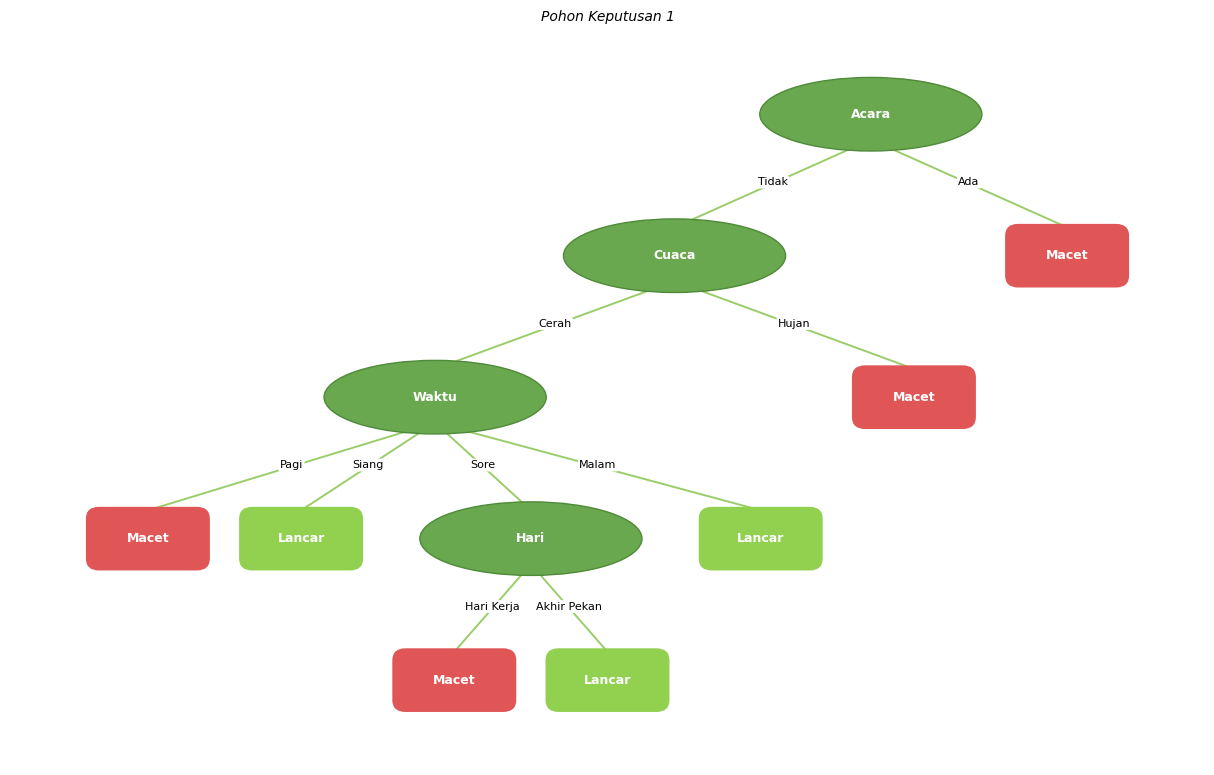

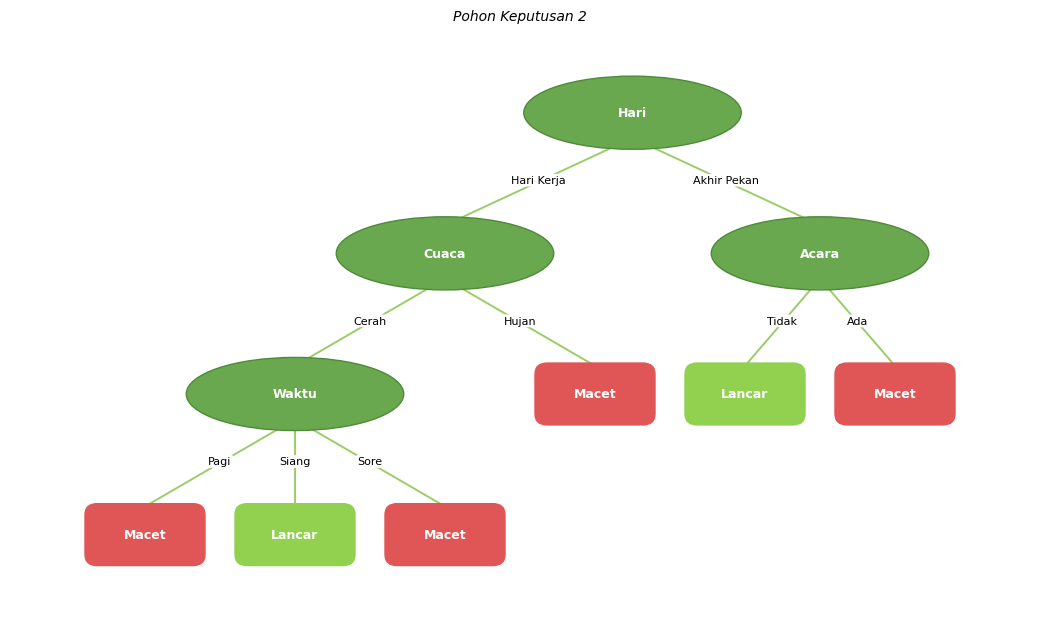

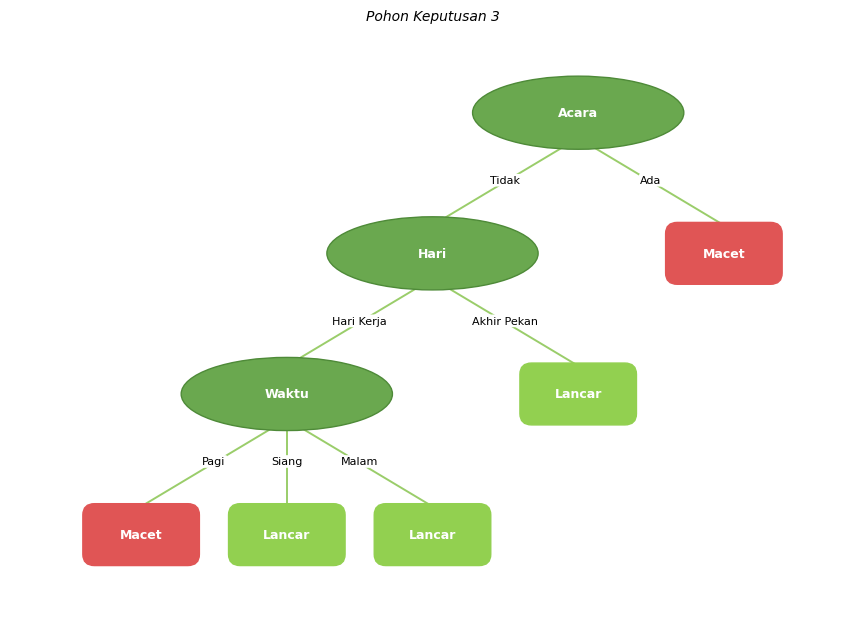

In [12]:
import matplotlib.pyplot as plt
import matplotlib

# Kembalikan backend ke inline agar gambar bisa muncul di Colab
%matplotlib inline
matplotlib.use('module://ipykernel.pylab.backend_inline')

for t in forest['trees']:
    fig = rf.draw_tree(t['tree'], title=f"Pohon Keputusan {t['index']}")
    # Tampilkan figur secara eksplisit
    display(fig)
    plt.close(fig)

## 7. Langkah 5 — Klasifikasi data baru dengan mayoritas vote

In [7]:
sample = {'Waktu': 'Sore', 'Hari': 'Hari Kerja', 'Cuaca': 'Hujan', 'Acara': 'Tidak'}
hasil = rf.predict_forest(forest, sample)
for v in hasil['votes']:
    jalur = ' -> '.join(f"{p['attr']}={p['value']}" for p in v['path'])
    print(f"Pohon {v['tree']}: {v['label']:<7} ({jalur})")
print('Suara:', hasil['counts'])
print('Prediksi akhir:', hasil['final'])

Pohon 1: Macet   (Acara=Tidak -> Cuaca=Hujan)
Pohon 2: Macet   (Hari=Hari Kerja -> Cuaca=Hujan)
Pohon 3: Lancar  (Acara=Tidak -> Hari=Hari Kerja)
Suara: {'Lancar': 1, 'Macet': 2}
Prediksi akhir: Macet


## 8. Evaluasi singkat
Data hanya 14 baris, jadi angka berikut sekadar gambaran (bukan klaim performa umum).

In [8]:
# Akurasi pada data latih
benar = sum(rf.predict_forest(forest, r)['final'] == r[rf.TARGET] for r in data)
print(f'Akurasi data latih: {benar}/{len(data)} = {benar/len(data):.2%}')

# Leave-One-Out: bangun ulang hutan tanpa 1 baris, uji pada baris itu
loo = 0
for i, r in enumerate(data):
    sisa = data[:i] + data[i+1:]
    f = rf.build_forest(sisa, n_trees=N_TREES, m=M_ATTR, seed=SEED)
    loo += rf.predict_forest(f, r)['final'] == r[rf.TARGET]
print(f'Akurasi Leave-One-Out: {loo}/{len(data)} = {loo/len(data):.2%}')

Akurasi data latih: 14/14 = 100.00%
Akurasi Leave-One-Out: 9/14 = 64.29%


## 9. Simpan model `.joblib`
Model disimpan sebagai struktur dict sederhana (list/dict/angka), sehingga bisa dimuat tanpa harus mengimpor kelas khusus.

In [9]:
MODEL_PATH = BASE / 'models' / 'rf_kemacetan.joblib'
paket = {
    'forest': forest,
    'dataset': data,
    'meta': {'judul': 'Random Forest Prediksi Kemacetan Lalu Lintas',
             'n_trees': N_TREES, 'm': M_ATTR, 'seed': SEED,
             'attrs': rf.ATTRS, 'domains': rf.DOMAINS, 'classes': rf.CLASSES},
}
joblib.dump(paket, MODEL_PATH, compress=3)

# Verifikasi: muat ulang dan bandingkan prediksi
cek = joblib.load(MODEL_PATH)
assert rf.predict_forest(cek['forest'], sample)['final'] == hasil['final']
print('Model tersimpan di', MODEL_PATH.resolve(), f'({MODEL_PATH.stat().st_size/1024:.1f} KB)')

Model tersimpan di /content/models/rf_kemacetan.joblib (2.5 KB)


## 10. (Opsional, Colab) Unduh model

In [10]:
try:
    from google.colab import files
    files.download(str(MODEL_PATH))
except ImportError:
    print('Bukan Colab: salin models/rf_kemacetan.joblib ke folder project/models/.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>